In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
%matplotlib inline

os.makedirs('output', exist_ok=True)
print("Setup complete.")

Setup complete.


Image dimensions: 1332 x 1529 pixels


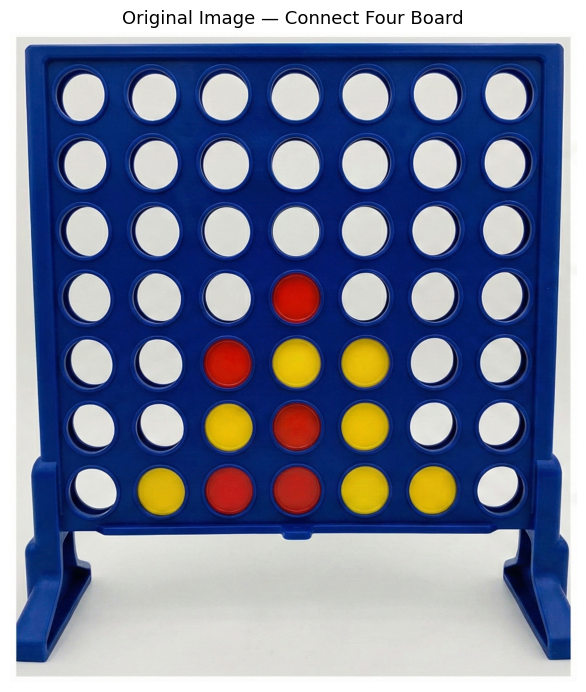

In [3]:
img_bgr = cv2.imread('board_sample.png')
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
gray    = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
H, W    = img_bgr.shape[:2]
print(f"Image dimensions: {W} x {H} pixels")

plt.figure(figsize=(6, 7))
plt.imshow(img_rgb)
plt.title('Original Image — Connect Four Board', fontsize=13)
plt.axis('off')
plt.tight_layout()
plt.savefig('output/m2_input_board.png', dpi=150, bbox_inches='tight')
plt.show()

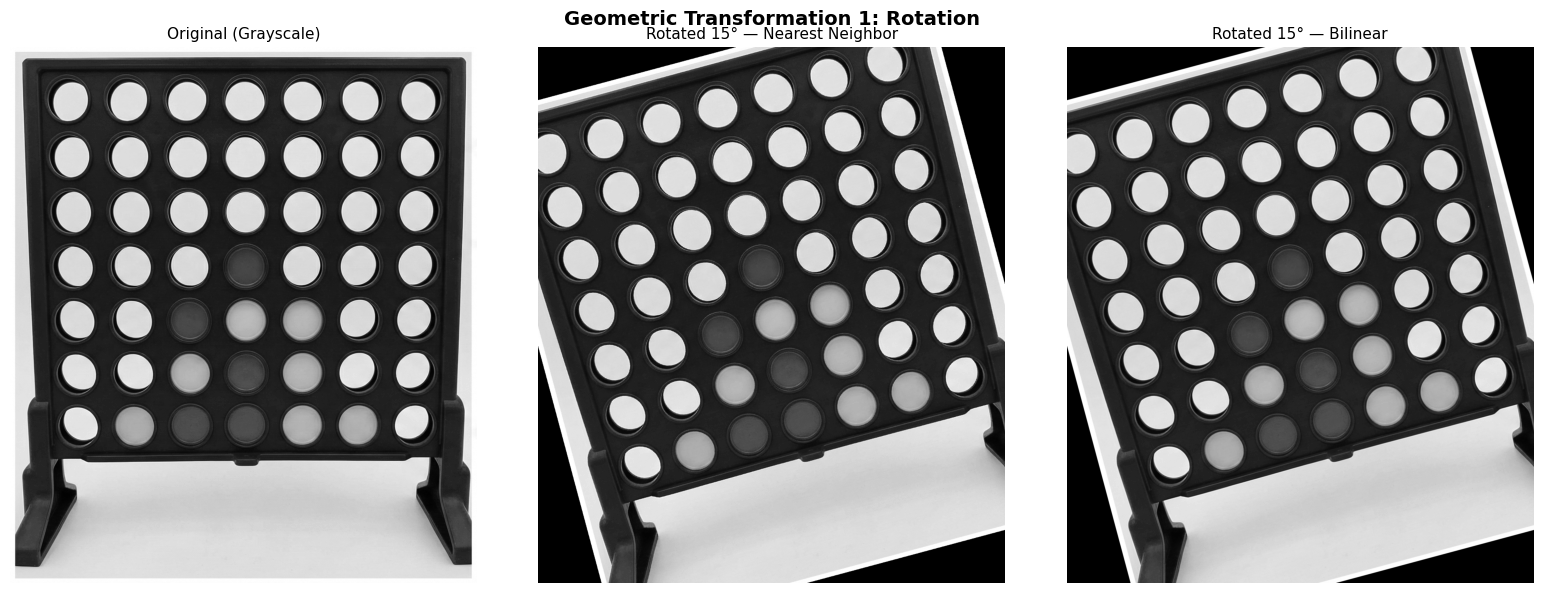

NN: jagged edges around circle boundaries.
Bilinear: smoother boundaries by averaging surrounding pixel intensities.


In [4]:
center = (W // 2, H // 2)
angle  = 15  # degrees CCW

M_rot  = cv2.getRotationMatrix2D(center, angle, scale=1.0)
rot_nn = cv2.warpAffine(gray, M_rot, (W, H), flags=cv2.INTER_NEAREST)
rot_bl = cv2.warpAffine(gray, M_rot, (W, H), flags=cv2.INTER_LINEAR)

fig, axes = plt.subplots(1, 3, figsize=(16, 6))
for ax, im, title in zip(axes,
    [gray, rot_nn, rot_bl],
    ['Original (Grayscale)', f'Rotated {angle}° — Nearest Neighbor', f'Rotated {angle}° — Bilinear']):
    ax.imshow(im, cmap='gray')
    ax.set_title(title, fontsize=11)
    ax.axis('off')
plt.suptitle('Geometric Transformation 1: Rotation', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('output/m2_rotation_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("NN: jagged edges around circle boundaries.")
print("Bilinear: smoother boundaries by averaging surrounding pixel intensities.")

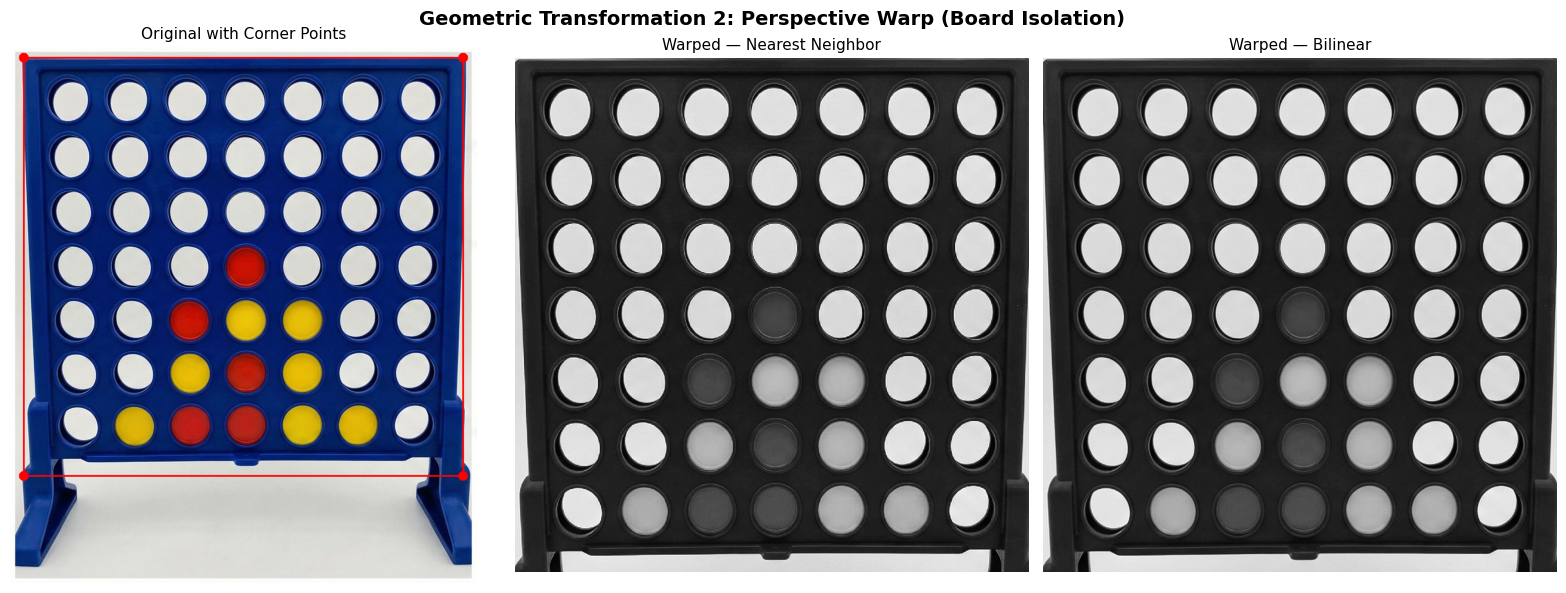

Warp isolates the board to a top-down orthographic view.
Critical for mapping circle pixel positions to grid indices in the project.


In [5]:
# Board corners: top-left, top-right, bottom-right, bottom-left
# These are estimated — adjust the multipliers slightly if the warp looks off
pts_src = np.float32([
    [int(W * 0.03), int(H * 0.02)],
    [int(W * 0.97), int(H * 0.02)],
    [int(W * 0.97), int(H * 0.80)],
    [int(W * 0.03), int(H * 0.80)],
])

out_w, out_h = 800, 800
pts_dst = np.float32([[0,0],[out_w,0],[out_w,out_h],[0,out_h]])
M_warp  = cv2.getPerspectiveTransform(pts_src, pts_dst)

warp_nn = cv2.warpPerspective(gray, M_warp, (out_w, out_h), flags=cv2.INTER_NEAREST)
warp_bl = cv2.warpPerspective(gray, M_warp, (out_w, out_h), flags=cv2.INTER_LINEAR)

img_pts = img_rgb.copy()
cv2.polylines(img_pts, [pts_src.astype(int).reshape(-1,1,2)], True, (255,0,0), 4)
for pt in pts_src.astype(int):
    cv2.circle(img_pts, tuple(pt), 14, (255,0,0), -1)

fig, axes = plt.subplots(1, 3, figsize=(16, 6))
for ax, im, title, cmap in zip(axes,
    [img_pts, warp_nn, warp_bl],
    ['Original with Corner Points', 'Warped — Nearest Neighbor', 'Warped — Bilinear'],
    [None, 'gray', 'gray']):
    ax.imshow(im, cmap=cmap)
    ax.set_title(title, fontsize=11)
    ax.axis('off')
plt.suptitle('Geometric Transformation 2: Perspective Warp (Board Isolation)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('output/m2_perspective_warp.png', dpi=150, bbox_inches='tight')
plt.show()
print("Warp isolates the board to a top-down orthographic view.")
print("Critical for mapping circle pixel positions to grid indices in the project.")

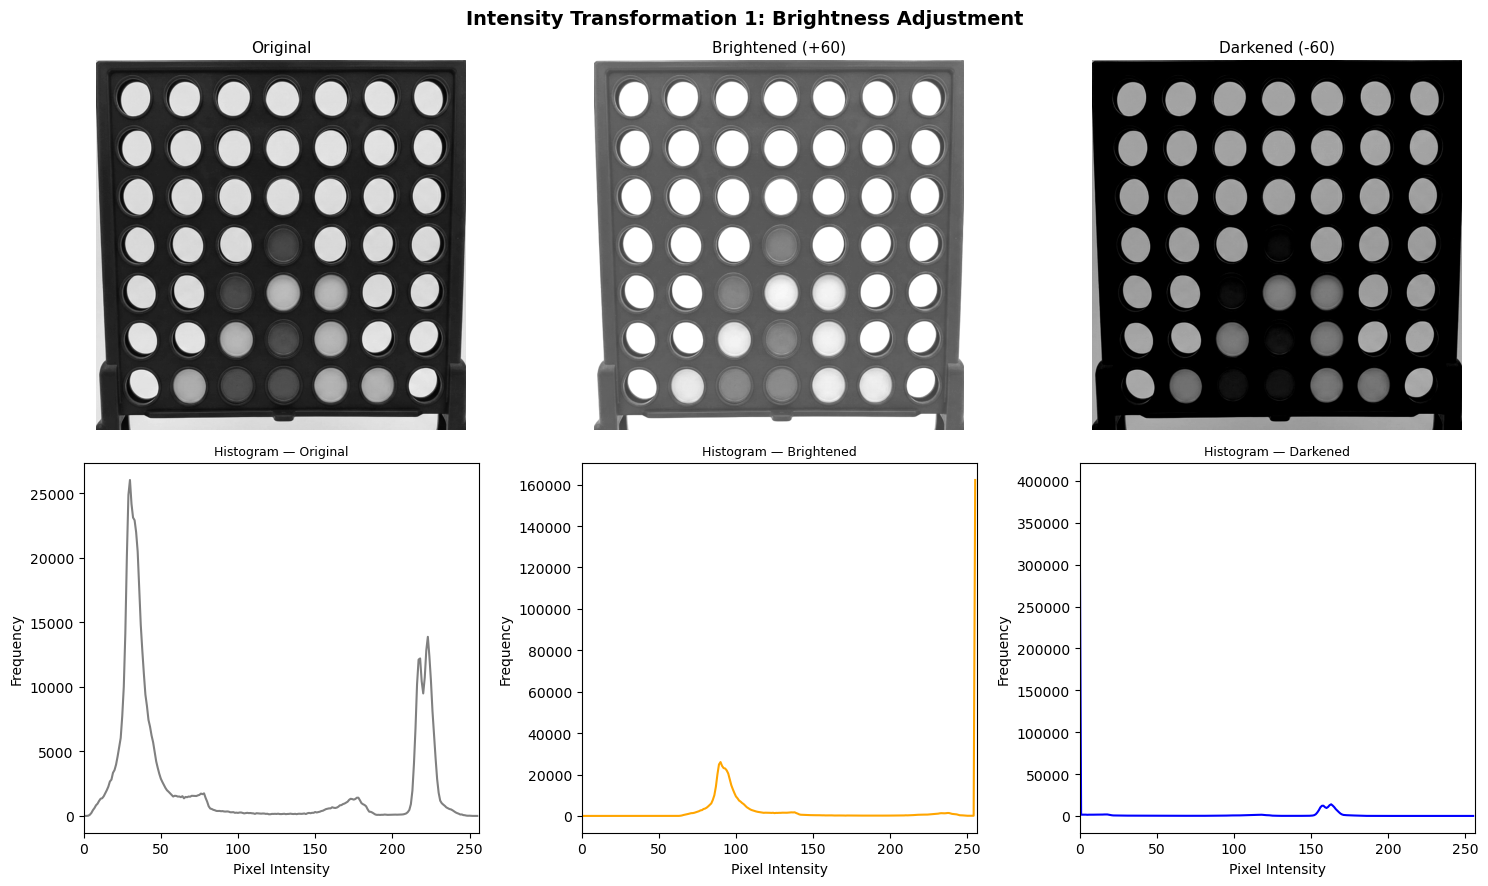

Mean — Original: 91.19 | Brightened: 144.46 | Darkened: 47.86


In [6]:
gray_warped = warp_bl.copy()
c           = 60
brightened  = cv2.add(gray_warped, c)
darkened    = cv2.subtract(gray_warped, c)

def plot_hist(ax, image, title, color):
    hist = cv2.calcHist([image], [0], None, [256], [0,256])
    ax.plot(hist, color=color)
    ax.set_title(title, fontsize=9)
    ax.set_xlim([0, 256])
    ax.set_xlabel('Pixel Intensity')
    ax.set_ylabel('Frequency')

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, im, title in zip(axes[0],
    [gray_warped, brightened, darkened],
    ['Original', f'Brightened (+{c})', f'Darkened (-{c})']):
    ax.imshow(im, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title, fontsize=11)
    ax.axis('off')
for ax, im, title, col in zip(axes[1],
    [gray_warped, brightened, darkened],
    ['Histogram — Original', 'Histogram — Brightened', 'Histogram — Darkened'],
    ['gray', 'orange', 'blue']):
    plot_hist(ax, im, title, col)
plt.suptitle('Intensity Transformation 1: Brightness Adjustment', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('output/m2_brightness_adjustment.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Mean — Original: {np.mean(gray_warped):.2f} | Brightened: {np.mean(brightened):.2f} | Darkened: {np.mean(darkened):.2f}")

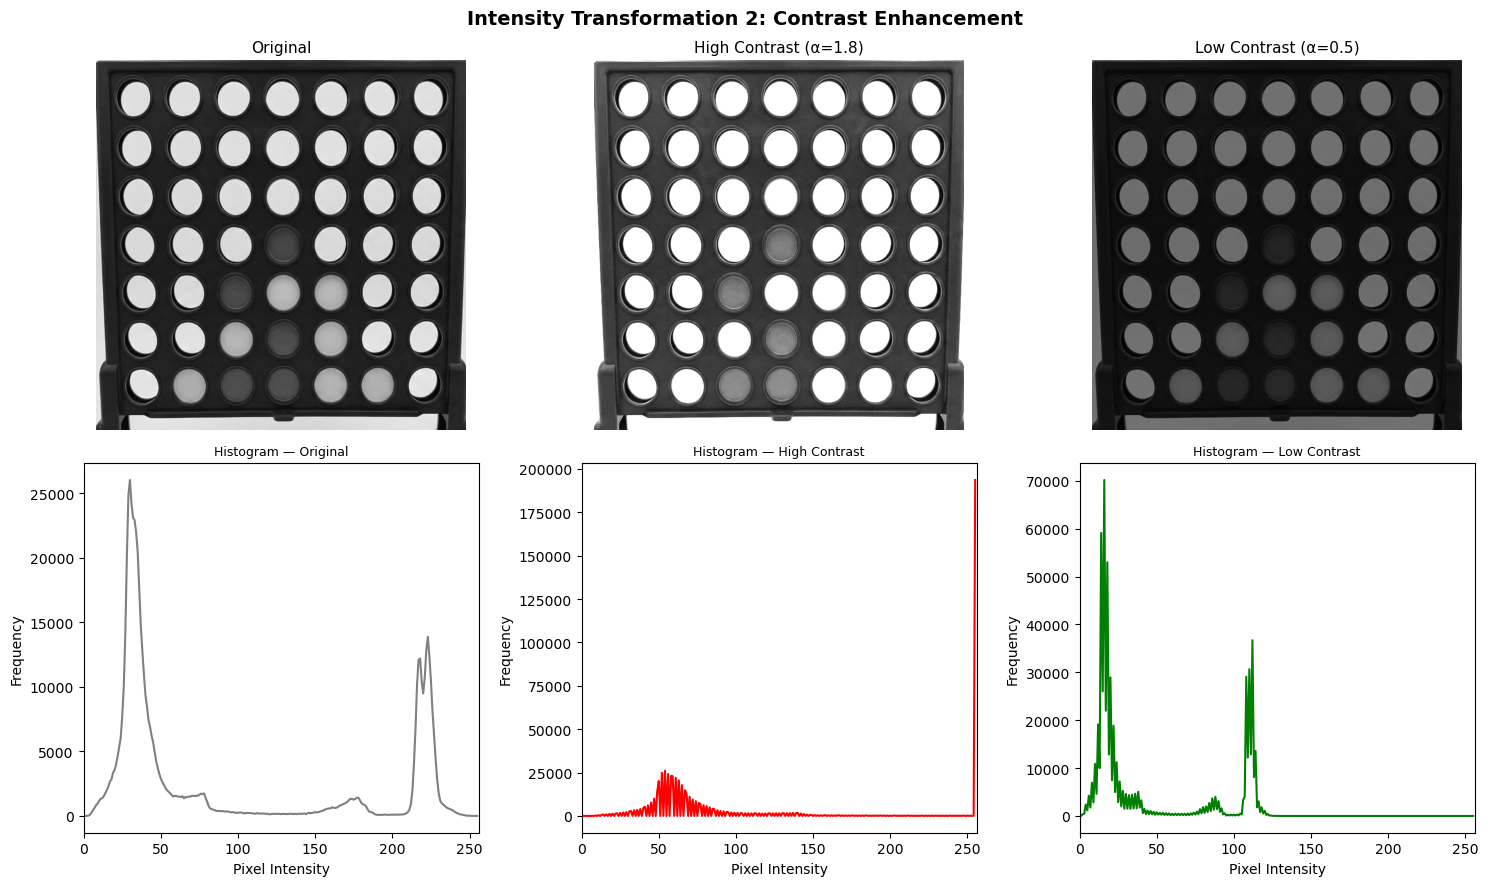

In [7]:
contrast_hi = cv2.convertScaleAbs(gray_warped, alpha=1.8, beta=0)
contrast_lo = cv2.convertScaleAbs(gray_warped, alpha=0.5, beta=0)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, im, title in zip(axes[0],
    [gray_warped, contrast_hi, contrast_lo],
    ['Original', 'High Contrast (α=1.8)', 'Low Contrast (α=0.5)']):
    ax.imshow(im, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title, fontsize=11)
    ax.axis('off')
for ax, im, title, col in zip(axes[1],
    [gray_warped, contrast_hi, contrast_lo],
    ['Histogram — Original', 'Histogram — High Contrast', 'Histogram — Low Contrast'],
    ['gray', 'red', 'green']):
    plot_hist(ax, im, title, col)
plt.suptitle('Intensity Transformation 2: Contrast Enhancement', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('output/m2_contrast_scaling.png', dpi=150, bbox_inches='tight')
plt.show()

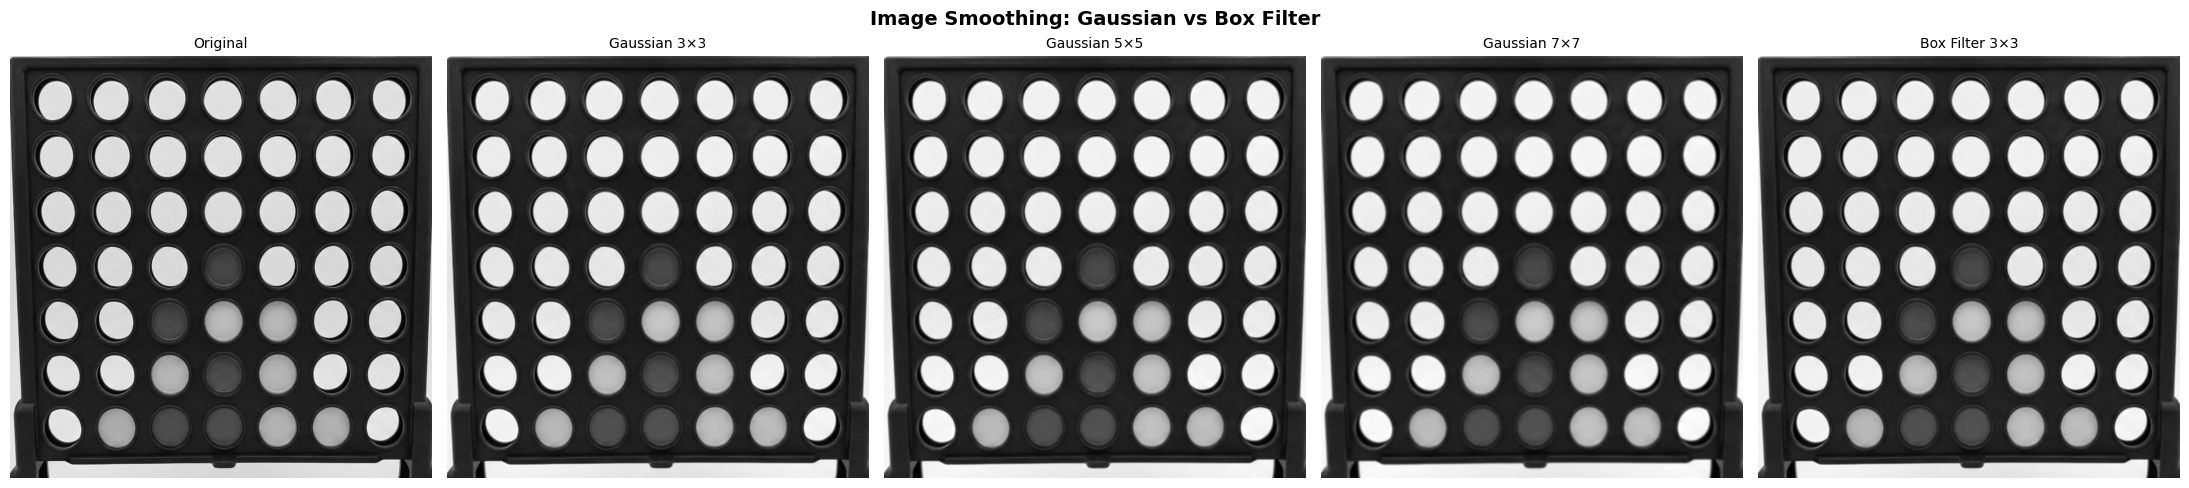

Larger kernel → more noise removed, but more edge/detail loss.
Gaussian weights center pixel more than Box — more natural blur.
Project will use Gaussian 5×5 as the balance point.


In [8]:
g3  = cv2.GaussianBlur(gray_warped, (3,3), 0)
g5  = cv2.GaussianBlur(gray_warped, (5,5), 0)
g7  = cv2.GaussianBlur(gray_warped, (7,7), 0)
box = cv2.blur(gray_warped, (3,3))

fig, axes = plt.subplots(1, 5, figsize=(22, 5))
for ax, im, title in zip(axes,
    [gray_warped, g3, g5, g7, box],
    ['Original', 'Gaussian 3×3', 'Gaussian 5×5', 'Gaussian 7×7', 'Box Filter 3×3']):
    ax.imshow(im, cmap='gray')
    ax.set_title(title, fontsize=10)
    ax.axis('off')
plt.suptitle('Image Smoothing: Gaussian vs Box Filter', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('output/m2_smoothing_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Larger kernel → more noise removed, but more edge/detail loss.")
print("Gaussian weights center pixel more than Box — more natural blur.")
print("Project will use Gaussian 5×5 as the balance point.")

In [9]:
feature_1 = float(np.mean(gray_warped))
feature_2 = float(np.degrees(np.arctan2(M_rot[1,0], M_rot[0,0])))

print("=" * 50)
print("  EXTRACTED FEATURES FOR CLOSED LOOP")
print("=" * 50)
print(f"  Feature 1 — Mean Board Brightness : {feature_1:.2f}  (range 0–255)")
print(f"  Feature 2 — Board Rotation Angle  : {feature_2:.2f}° (range -180 to 180)")
print()
print("  Motor Mapping (send to Member 2):")
print(f"    Brightness → Motor speed = {int(feature_1/255*100)}% of max PWM")
print(f"    Angle {feature_2:.1f}°  → Direction: {'CW' if feature_2 > 0 else 'CCW'}")
print("=" * 50)

  EXTRACTED FEATURES FOR CLOSED LOOP
  Feature 1 — Mean Board Brightness : 91.19  (range 0–255)
  Feature 2 — Board Rotation Angle  : -15.00° (range -180 to 180)

  Motor Mapping (send to Member 2):
    Brightness → Motor speed = 35% of max PWM
    Angle -15.0°  → Direction: CCW


In [10]:
import os

files = os.listdir('output')
print("=== OUTPUT FILES ===")
for f in sorted(files):
    size = os.path.getsize(f'output/{f}')
    print(f"  {f} — {size:,} bytes")

print("\n=== IMAGE DIMENSIONS ===")
print(f"  Original : {W} x {H}")
print(f"  Warped   : {out_w} x {out_h}")

print("\n=== FEATURE VALUES ===")
print(f"  Feature 1 — Mean Brightness : {feature_1:.2f}")
print(f"  Feature 2 — Rotation Angle  : {feature_2:.2f}°")

print("\n=== CELL STATUS ===")
for i, name in enumerate([
    "Imports & Setup",
    "Load & Display",
    "Rotation",
    "Perspective Warp",
    "Brightness",
    "Contrast",
    "Smoothing",
    "Feature Extraction"
], 1):
    print(f"  Cell {i} — {name} : OK")

=== OUTPUT FILES ===
  m2_input_board.png — 1,239,356 bytes
  m2_rotation_comparison.png — 1,343,662 bytes
  m2_perspective_warp.png — 1,991,344 bytes
  m2_brightness_adjustment.png — 737,604 bytes
  m2_contrast_scaling.png — 871,234 bytes
  m2_smoothing_comparison.png — 1,349,053 bytes

=== IMAGE DIMENSIONS ===
  Original : 1332 x 1529
  Warped   : 800 x 800

=== FEATURE VALUES ===
  Feature 1 — Mean Brightness : 91.19
  Feature 2 — Rotation Angle  : -15.00°

=== CELL STATUS ===
  Cell 1 — Imports & Setup : OK
  Cell 2 — Load & Display : OK
  Cell 3 — Rotation : OK
  Cell 4 — Perspective Warp : OK
  Cell 5 — Brightness : OK
  Cell 6 — Contrast : OK
  Cell 7 — Smoothing : OK
  Cell 8 — Feature Extraction : OK


In [11]:
import time

tasks = {
    "Rotation (Bilinear)"  : lambda: cv2.warpAffine(gray, M_rot, (W,H), flags=cv2.INTER_LINEAR),
    "Perspective Warp"     : lambda: cv2.warpPerspective(gray, M_warp, (800,800)),
    "Brightness +60"       : lambda: cv2.add(gray_warped, 60),
    "Contrast α=1.8"       : lambda: cv2.convertScaleAbs(gray_warped, alpha=1.8),
    "Gaussian Blur 5×5"    : lambda: cv2.GaussianBlur(gray_warped, (5,5), 0),
}

print(f"{'Task':<25} {'Pi (ms)':>10}")
print("-" * 37)
for name, fn in tasks.items():
    t0 = time.perf_counter()
    for _ in range(100):
        fn()
    elapsed = (time.perf_counter() - t0) / 100 * 1000
    print(f"{name:<25} {elapsed:>9.3f} ms")

Task                         Pi (ms)
-------------------------------------
Rotation (Bilinear)           3.273 ms
Perspective Warp              1.768 ms
Brightness +60                0.888 ms
Contrast α=1.8                0.201 ms
Gaussian Blur 5×5             0.097 ms
